<a href="https://colab.research.google.com/github/BaichalMiras/PII_BaichalMiras_2-CS/blob/main/%D0%9C%D0%B8%D1%80%D0%B0%D1%81_2_CS_%D0%9F%D1%80%D0%B0%D0%BA%D1%82%D0%B8%D0%BA%D0%B02.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

## 1. Подготовка данных

X shape: (300, 2)
y shape: (300,)


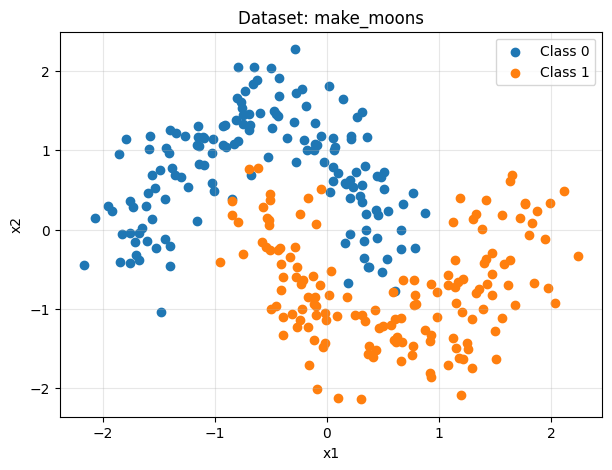

In [24]:
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.preprocessing import StandardScaler

np.random.seed(42)

X, y = make_moons(
    n_samples=300,
    noise=0.18,
    random_state=42
)

X = StandardScaler().fit_transform(X)

print("X shape:", X.shape)
print("y shape:", y.shape)

plt.figure(figsize=(7, 5))
plt.scatter(X[y == 0, 0], X[y == 0, 1], label="Class 0")
plt.scatter(X[y == 1, 0], X[y == 1, 1], label="Class 1")
plt.xlabel("x1")
plt.ylabel("x2")
plt.title("Dataset: make_moons")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


Можно ли провести одну прямую, которая идеально разделит два класса? Нет, потому что датасет make_moons два класса имеют изогнутую форму и окружают друг друга. Поэтому одной прямой невозможно полностью отделить один класс от другого.

## 2. Проверка одного персептрона

Accuracy: 0.8833333333333333


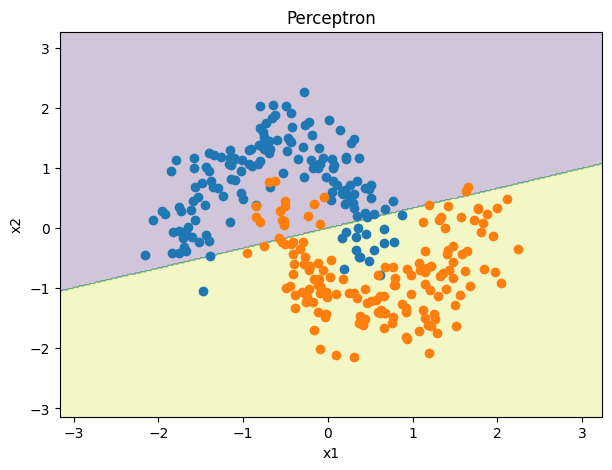

In [25]:
from sklearn.linear_model import Perceptron
from sklearn.metrics import accuracy_score

p = Perceptron(max_iter=1000, random_state=42)
p.fit(X, y)

pred = p.predict(X)
print("Accuracy:", accuracy_score(y, pred))

def plot_boundary(model, X, y, title):
    x_min, x_max = X[:, 0].min() - 1, X[:, 0].max() + 1
    y_min, y_max = X[:, 1].min() - 1, X[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 300),
        np.linspace(y_min, y_max, 300)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]
    z = model.predict(grid).reshape(xx.shape)

    plt.figure(figsize=(7, 5))
    plt.contourf(xx, yy, z, alpha=0.25)
    plt.scatter(X[y == 0, 0], X[y == 0, 1])
    plt.scatter(X[y == 1, 0], X[y == 1, 1])
    plt.xlabel("x1")
    plt.ylabel("x2")
    plt.title(title)
    plt.show()

plot_boundary(p, X, y, "Perceptron")

### Ответы
Изменяется ли принципиальная способность персептрона строить нелинейную границу?
Нет. Изменение noise влияет на расположение точек и полученную accuracy, но сам персептрон всё равно строит только линейную границу.

Полученные значения accuracy: при запуске могут немного зависеть от версии библиотек, но в текущем запуске: 0.05 - 0.867, 0.18 - 0.883, 0.35 - 0.793

## 3. Функции активации

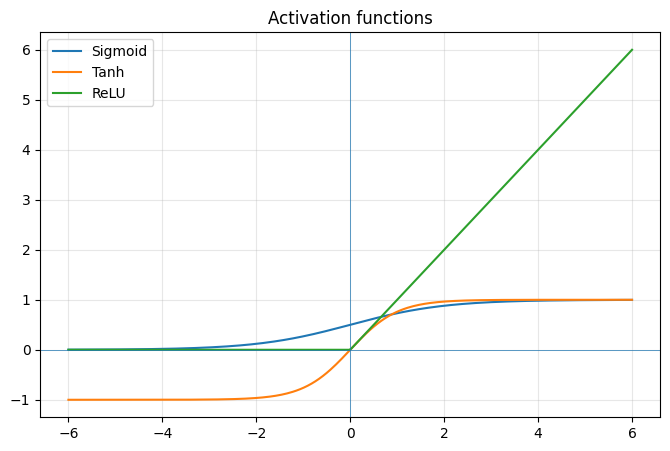

In [26]:
def sigmoid(z):
    return 1 / (1 + np.exp(-np.clip(z, -40, 40)))

def relu(z):
    return np.maximum(0, z)

def tanh(z):
    return np.tanh(z)

z = np.linspace(-6, 6, 300)

plt.figure(figsize=(8, 5))
plt.plot(z, sigmoid(z), label="Sigmoid")
plt.plot(z, tanh(z), label="Tanh")
plt.plot(z, relu(z), label="ReLU")
plt.axhline(0, linewidth=0.5)
plt.axvline(0, linewidth=0.5)
plt.legend()
plt.grid(alpha=0.3)
plt.title("Activation functions")
plt.show()

### Ответы
1. Почему sigmoid ограничена интервалом (0, 1)?
   Формула 1 / (1 + e^-z) всегда даёт значение строго между 0 и 1

2. Почему tanh принимает значения от -1 до 1?  
   Функция tanh(z) является гиперболическим тангенсом и по определению ограничена этими двумя значениями

3. Почему ReLU не ограничена сверху?  
   ReLU определяется как max(0, z). При положительном z она равна z, поэтому может расти неограниченно

4. Зачем нужна нелинейная функция активации?
   Она позволяет нейросети строить нелинейные зависимости. Без неё последовательность линейных слоёв сводилась бы к одной линейной функции

## 4. Forward pass многослойной сети

In [27]:
rng = np.random.default_rng(42)

W1 = rng.normal(0, 0.5, size=(2, 4))
b1 = np.zeros((1, 4))

W2 = rng.normal(0, 0.5, size=(4, 1))
b2 = np.zeros((1, 1))

print("W1:", W1.shape)
print("b1:", b1.shape)
print("W2:", W2.shape)
print("b2:", b2.shape)

Z1 = X @ W1 + b1
A1 = np.tanh(Z1)
Z2 = A1 @ W2 + b2
Y_prob = sigmoid(Z2)

print("X ", X.shape)
print("Z1", Z1.shape)
print("A1", A1.shape)
print("Z2", Z2.shape)
print("Y ", Y_prob.shape)

W1: (2, 4)
b1: (1, 4)
W2: (4, 1)
b2: (1, 1)
X  (300, 2)
Z1 (300, 4)
A1 (300, 4)
Z2 (300, 1)
Y  (300, 1)


### Ответы
Почему A1 имеет четыре столбца?
Потому что в скрытом слое четыре нейрона. Каждый нейрон выдаёт одно значение для каждого объекта

Что физически означает каждый столбец A1?
Каждый столбец содержит активации одного скрытого нейрона для всех 300 объектов.Это результат работы отдельного скрытого нейрона над входными признаками

## 5. Что делают скрытые нейроны

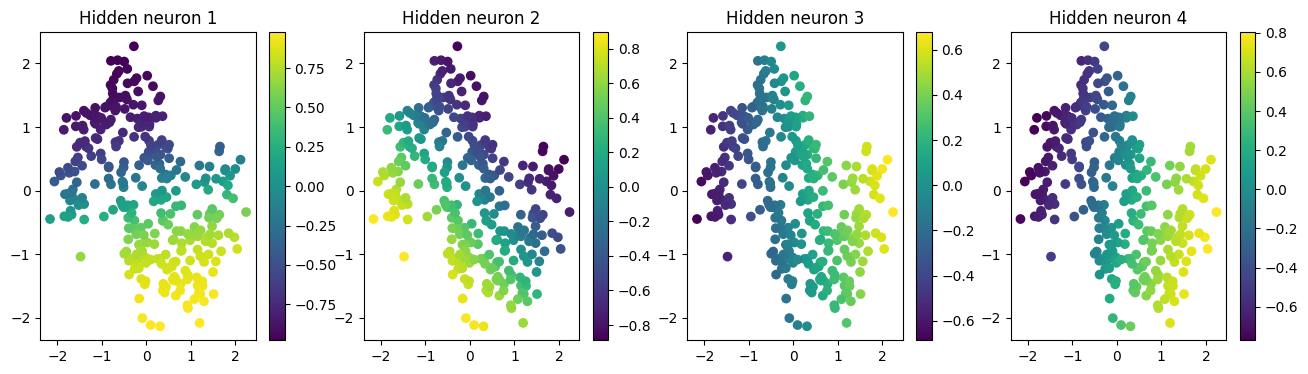

In [28]:
fig, axes = plt.subplots(1, 4, figsize=(16, 4))

for i in range(4):
    sc = axes[i].scatter(
        X[:, 0],
        X[:, 1],
        c=A1[:, i]
    )
    axes[i].set_title(f"Hidden neuron {i+1}")
    plt.colorbar(sc, ax=axes[i])

plt.show()

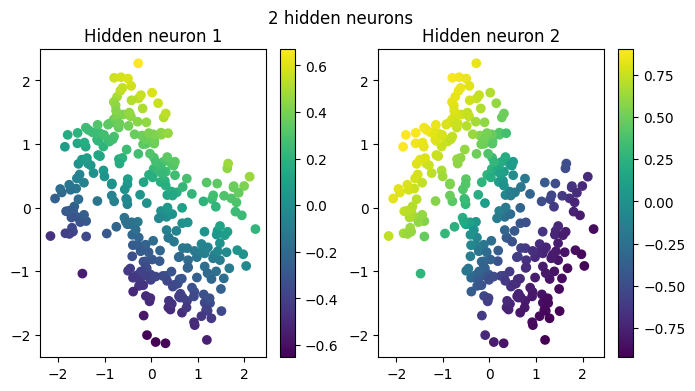

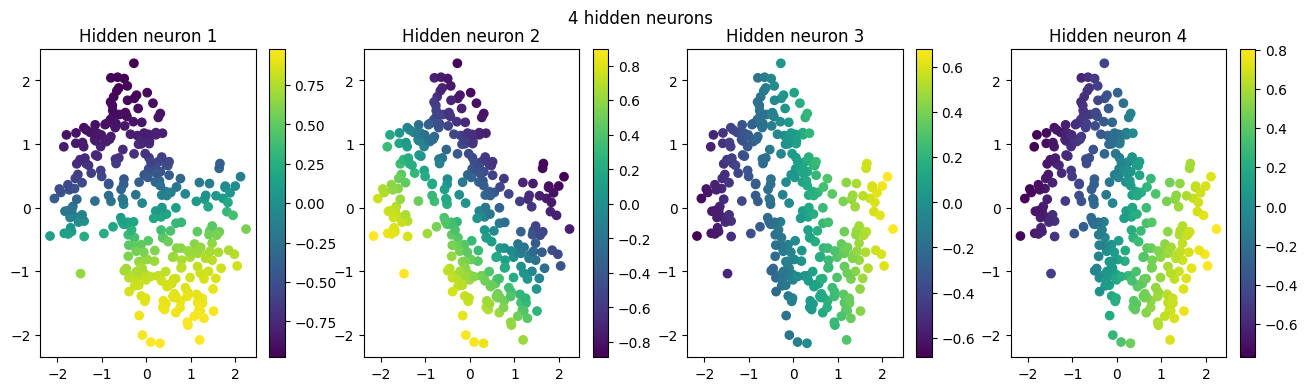

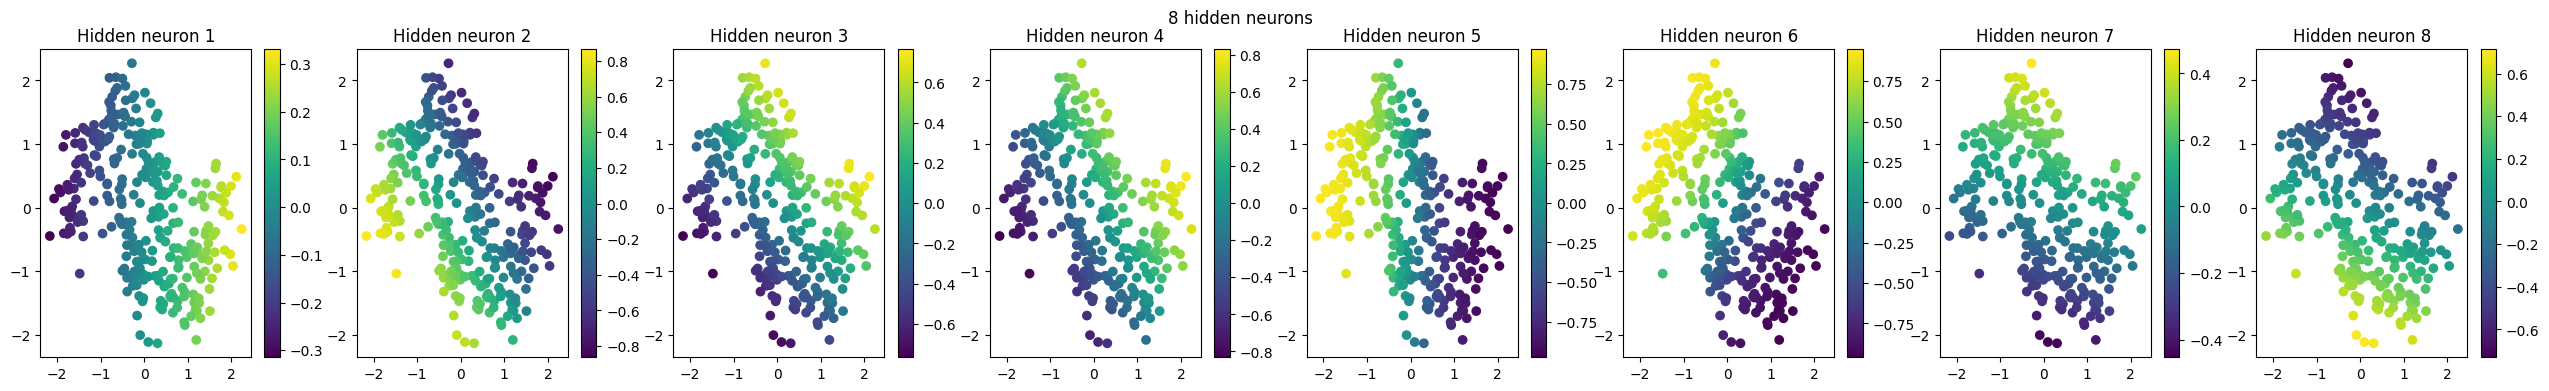

In [29]:
for n in [2, 4, 8]:
    rng = np.random.default_rng(42)

    W1 = rng.normal(0, 0.5, size=(2, n))
    b1 = np.zeros((1, n))

    W2 = rng.normal(0, 0.5, size=(n, 1))
    b2 = np.zeros((1, 1))

    Z1 = X @ W1 + b1
    A1 = np.tanh(Z1)

    fig, axes = plt.subplots(1, n, figsize=(4*n, 4))

    for i in range(n):
        sc = axes[i].scatter(
            X[:, 0],
            X[:, 1],
            c=A1[:, i]
        )
        axes[i].set_title(f"Hidden neuron {i+1}")
        plt.colorbar(sc, ax=axes[i])

    plt.suptitle(f"{n} hidden neurons")
    plt.show()

### Таблица наблюдений

hidden neurons:

2: Всего два признака, и оба это просто плавный переход цвета в одном направлении

4: Четыре разных "среза" данных, у каждого своё направление и разный размах значений. Нейроны 3 и 4 идут в одну сторону (слева направо, от тёмного к жёлтому), но отличаются в верхней части: у 3-го она бирюзовая, у 4-го тёмная

8: 	Признаков больше и направления разнообразнее, но часть нейронов направлена в одну сторону (5, 6 и 7 идут от жёлтого вверху слева к тёмному внизу справа), хотя значения у них разные. Нейрон 1 меняется только в пределах около +-0.3, то есть почти ничего не различает


## 6. Функция потерь

In [30]:
def bce(y_true, y_prob):
    y_true = y_true.reshape(-1, 1)
    eps = 1e-9
    y_prob = np.clip(y_prob, eps, 1-eps)

    return -np.mean(
        y_true*np.log(y_prob)
        + (1-y_true)*np.log(1-y_prob)
    )

loss = bce(y, Y_prob)
print("Loss:", loss)
print("Верный уверенный:", bce(np.array([1]), np.array([[0.99]])))
print("Верный неуверенный:", bce(np.array([1]), np.array([[0.55]])))
print("Уверенная ошибка:", bce(np.array([1]), np.array([[0.01]])))

Loss: 0.653752332372796
Верный уверенный: 0.01005033585350145
Верный неуверенный: 0.5978370007556204
Уверенная ошибка: 4.605170185988091


### Ответ
Какой случай штрафуется сильнее всего и почему? Сильнее всего штрафуется уверенная ошибка, то есть случай y=1, но модель предсказывает 0.01. Bсе сильно увеличивается, когда модель уверенно выдаёт вероятность неправильного класса. Это заставляет обучение сильнее исправлять такие ошибки

## 7. Backpropagation

In [31]:
y_col = y.reshape(-1, 1)
m = len(X)

dZ2 = (Y_prob - y_col) / m

dW2 = A1.T @ dZ2
db2 = np.sum(dZ2, axis=0, keepdims=True)

dA1 = dZ2 @ W2.T

dZ1 = dA1 * (1 - A1**2)

dW1 = X.T @ dZ1
db1 = np.sum(dZ1, axis=0, keepdims=True)

print("dW1", dW1.shape)
print("dW2", dW2.shape)

dW1 (2, 8)
dW2 (8, 1)


### Ответы
Почему dW1.shape должен совпадать с W1.shape? Потому что dW1 содержит производную функции потерь по каждому элементу матрицы W1. Для каждого веса нужен свой градиент.

Что показывает знак градиента конкретного веса? Знак показывает направление изменения функции потерь при увеличении этого веса: положительный градиент означает рост loss, отрицательный - уменьшение loss при увеличении веса.

Что означает большой модуль градиента? Большой модуль означает, что loss сильно чувствителен к этому весу. Такой вес сильнее влияет на ошибку модели.

## 8. Один шаг Gradient Descent

In [44]:
lr = 0.1

W1 = W1 - lr*dW1
b1 = b1 - lr*db1

W2 = W2 - lr*dW2
b2 = b2 - lr*db2

### Ответы
Почему используется минус перед gradient? Градиент указывает направление наибольшего роста функции потерь. Поэтому для уменьшения loss параметры двигаются в противоположную сторону -gradient

Какую роль играет learning rate? Learning rate определяет размер шага обновления весов. Маленький шаг делает обучение медленным, а слишком большой может сделать обучение нестабильным.

## 9. Полный цикл обучения

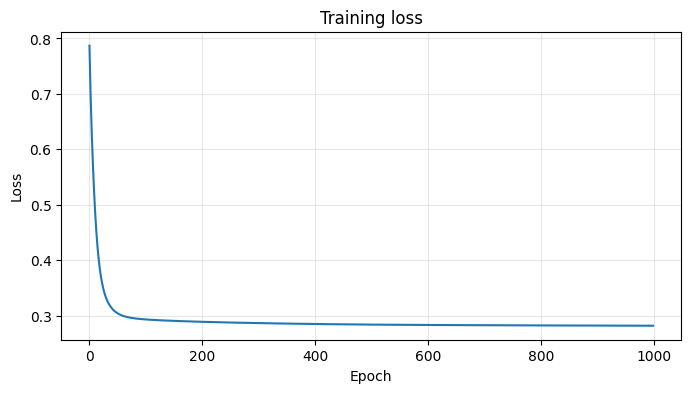

In [33]:
rng = np.random.default_rng(1)

W1 = rng.normal(0, np.sqrt(1/2), size=(2, 4))
b1 = np.zeros((1, 4))

W2 = rng.normal(0, np.sqrt(1/4), size=(4, 1))
b2 = np.zeros((1, 1))

lr = 0.3
losses = []

for epoch in range(1000):

    # FORWARD
    Z1 = X @ W1 + b1
    A1 = np.tanh(Z1)
    Z2 = A1 @ W2 + b2
    Y_prob = sigmoid(Z2)

    # LOSS
    loss = bce(y, Y_prob)
    losses.append(loss)

    # BACKWARD
    y_col = y.reshape(-1, 1)
    m = len(X)

    dZ2 = (Y_prob - y_col) / m
    dW2 = A1.T @ dZ2
    db2 = dZ2.sum(axis=0, keepdims=True)

    dA1 = dZ2 @ W2.T
    dZ1 = dA1 * (1-A1**2)

    dW1 = X.T @ dZ1
    db1 = dZ1.sum(axis=0, keepdims=True)

    # UPDATE
    W1 -= lr*dW1
    b1 -= lr*db1
    W2 -= lr*dW2
    b2 -= lr*db2

plt.figure(figsize=(8, 4))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training loss")
plt.grid(alpha=0.3)
plt.show()


## 10. Обязательные эксперименты

### Эксперимент A. Learning rate

lr = 0.001
Final loss: 0.6549395475959473
Accuracy: 0.66


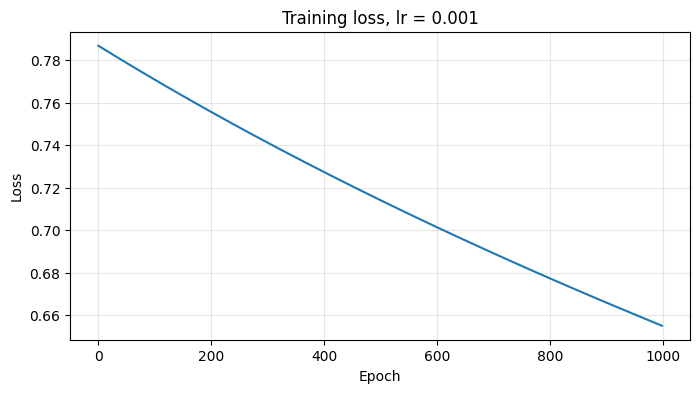

lr = 0.1
Final loss: 0.2858854058894602
Accuracy: 0.8833333333333333


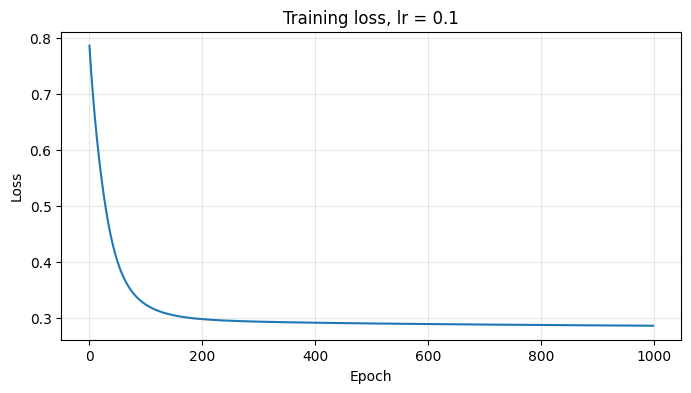

lr = 3.0
Final loss: 0.040635025025686104
Accuracy: 0.9833333333333333


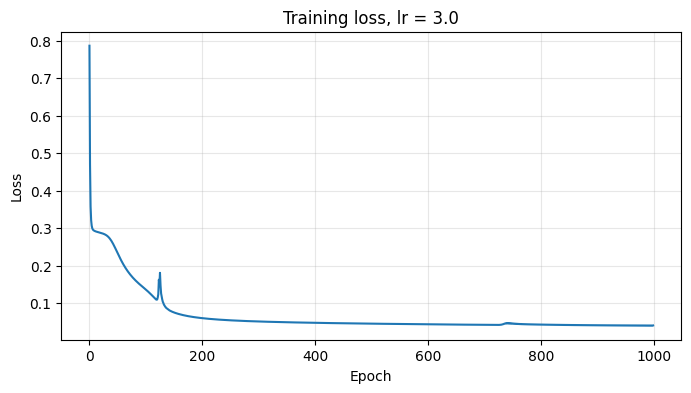

In [46]:
for lr in [0.001, 0.1, 3.0]:
    rng = np.random.default_rng(1)

    W1 = rng.normal(0, np.sqrt(1/2), size=(2, 4))
    b1 = np.zeros((1, 4))

    W2 = rng.normal(0, np.sqrt(1/4), size=(4, 1))
    b2 = np.zeros((1, 1))

    losses = []

    for epoch in range(1000):


        Z1 = X @ W1 + b1
        A1 = np.tanh(Z1)
        Z2 = A1 @ W2 + b2
        Y_prob = sigmoid(Z2)


        loss = bce(y, Y_prob)
        losses.append(loss)


        y_col = y.reshape(-1, 1)
        m = len(X)

        dZ2 = (Y_prob - y_col) / m
        dW2 = A1.T @ dZ2
        db2 = dZ2.sum(axis=0, keepdims=True)

        dA1 = dZ2 @ W2.T
        dZ1 = dA1 * (1-A1**2)

        dW1 = X.T @ dZ1
        db1 = dZ1.sum(axis=0, keepdims=True)


        W1 -= lr*dW1
        b1 -= lr*db1
        W2 -= lr*dW2
        b2 -= lr*db2

    print("lr =", lr)
    print("Final loss:", losses[-1])
    print("Accuracy:", accuracy_score(y, (Y_prob > 0.5).astype(int).ravel()))

    plt.figure(figsize=(8, 4))
    plt.plot(losses)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"Training loss, lr = {lr}")
    plt.grid(alpha=0.3)
    plt.show()

### Ответы
Что происходит при слишком маленьком learning rate? Шаги очень маленькие, и обучение идёт очень медленно. При lr = 0.001 за 1000 эпох loss опустился только с 0.79 до 0.65, accuracy 0.66. Сеть просто не успевает обучиться, нужно намного больше эпох.

Что происходит при слишком большом learning rate? Шаги обновления становятся слишком большими. Модель может перескакивать через минимум loss, обучение становится нестабильным и может ухудшаться. У меня при lr = 3.0 до расходимости не дошло, были только короткие всплески loss, эти всплески показывают начало нестабильности.

### Эксперимент B. Количество эпох

In [47]:
for n_epochs in [10, 100, 1000]:
    rng = np.random.default_rng(1)

    W1 = rng.normal(0, np.sqrt(1/2), size=(2, 4))
    b1 = np.zeros((1, 4))

    W2 = rng.normal(0, np.sqrt(1/4), size=(4, 1))
    b2 = np.zeros((1, 1))

    lr = 0.3
    losses = []

    for epoch in range(n_epochs):

        Z1 = X @ W1 + b1
        A1 = np.tanh(Z1)
        Z2 = A1 @ W2 + b2
        Y_prob = sigmoid(Z2)


        loss = bce(y, Y_prob)
        losses.append(loss)


        y_col = y.reshape(-1, 1)
        m = len(X)

        dZ2 = (Y_prob - y_col) / m
        dW2 = A1.T @ dZ2
        db2 = dZ2.sum(axis=0, keepdims=True)

        dA1 = dZ2 @ W2.T
        dZ1 = dA1 * (1-A1**2)

        dW1 = X.T @ dZ1
        db1 = dZ1.sum(axis=0, keepdims=True)


        W1 -= lr*dW1
        b1 -= lr*db1
        W2 -= lr*dW2
        b2 -= lr*db2

    print("Epochs:", n_epochs)
    print("Final loss:", losses[-1])
    print("Accuracy:", accuracy_score(y, (Y_prob > 0.5).astype(int).ravel()))
    print()

Epochs: 10
Final loss: 0.5070116193857541
Accuracy: 0.8333333333333334

Epochs: 100
Final loss: 0.29318836229820205
Accuracy: 0.8833333333333333

Epochs: 1000
Final loss: 0.2818146159965498
Accuracy: 0.8766666666666667



### Таблица результатов

epochs 10: final loss: 0.5070, Accuracy: 0.833
epochs 100: final loss: 0.2932, Accuracy: 0.883
epochs 1000: final loss: 0.2818, Accuracy: 0.877

Основное обучение происходит в первые 100 эпох, дальше улучшение совсем маленькое. Accuracy при этом чуть просела с 0.883 до 0.877, хотя loss стал меньше. Значит loss и accuracy не обязаны меняться синхронно

### Эксперимент C. Activation Battle

Activation: sigmoid
Final loss: 0.28586963377026603
Accuracy: 0.88


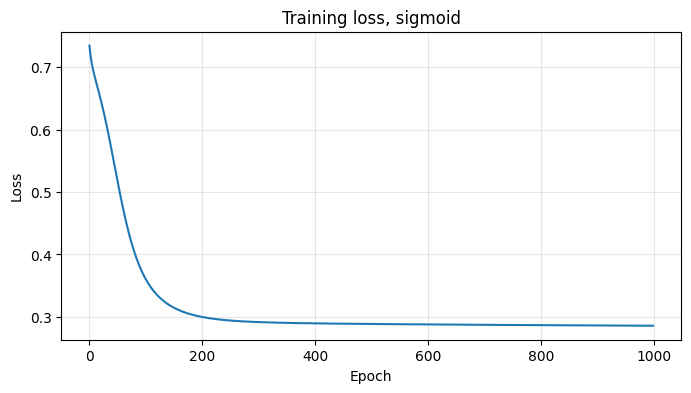

Activation: tanh
Final loss: 0.2818146159965498
Accuracy: 0.8766666666666667


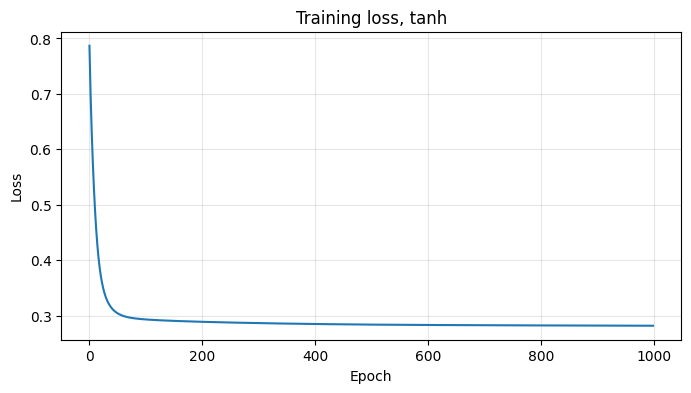

Activation: relu
Final loss: 0.08980692452468046
Accuracy: 0.9666666666666667


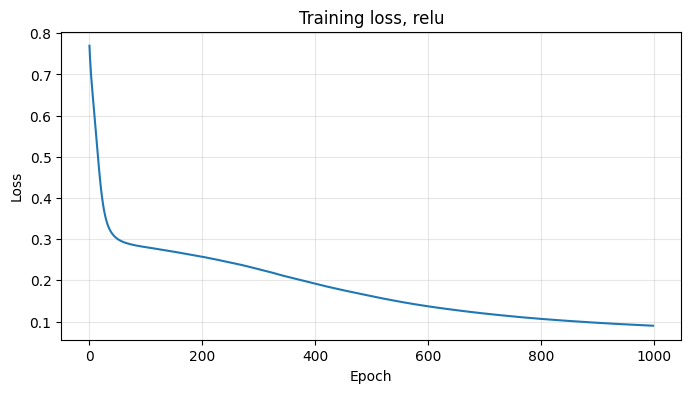

In [50]:
for name in ["sigmoid", "tanh", "relu"]:
    rng = np.random.default_rng(1)

    W1 = rng.normal(0, np.sqrt(1/2), size=(2, 4))
    b1 = np.zeros((1, 4))

    W2 = rng.normal(0, np.sqrt(1/4), size=(4, 1))
    b2 = np.zeros((1, 1))

    lr = 0.3
    losses = []

    for epoch in range(1000):


        Z1 = X @ W1 + b1
        if name == "sigmoid":
            A1 = sigmoid(Z1)
        elif name == "tanh":
            A1 = np.tanh(Z1)
        else:
            A1 = relu(Z1)
        Z2 = A1 @ W2 + b2
        Y_prob = sigmoid(Z2)


        loss = bce(y, Y_prob)
        losses.append(loss)


        y_col = y.reshape(-1, 1)
        m = len(X)

        dZ2 = (Y_prob - y_col) / m
        dW2 = A1.T @ dZ2
        db2 = dZ2.sum(axis=0, keepdims=True)

        dA1 = dZ2 @ W2.T
        if name == "sigmoid":
            dZ1 = dA1 * A1 * (1-A1)
        elif name == "tanh":
            dZ1 = dA1 * (1-A1**2)
        else:
            dZ1 = dA1 * (Z1 > 0)

        dW1 = X.T @ dZ1
        db1 = dZ1.sum(axis=0, keepdims=True)


        W1 -= lr*dW1
        b1 -= lr*db1
        W2 -= lr*dW2
        b2 -= lr*db2

    print("Activation:", name)
    print("Final loss:", losses[-1])
    print("Accuracy:", accuracy_score(y, (Y_prob > 0.5).astype(int).ravel()))

    plt.figure(figsize=(8, 4))
    plt.plot(losses)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"Training loss, {name}")
    plt.grid(alpha=0.3)
    plt.show()


### Таблица результатов

Sigmoid: final loss: 0.2859, Accuracy: 0.88, Наблюдения: самый медленный старт: loss около 0.73 в начале и выходит на плато только к 200-й эпохе (у tanh к 50-й)

tahn: final loss: 0.2812 Accuracy: 0.877, Наблюдения: быстро падает, потом плато около 0.28, почти как у линейной модели

ReLU: final loss: 0.0898, Accuracy: 0.967, Наблюдения: после такого же плато loss продолжил падать и к концу вышел заметно лучше остальных

### Эксперимент D. Что будет без activation?

Final loss: 0.27809680625029176
Accuracy: 0.8733333333333333


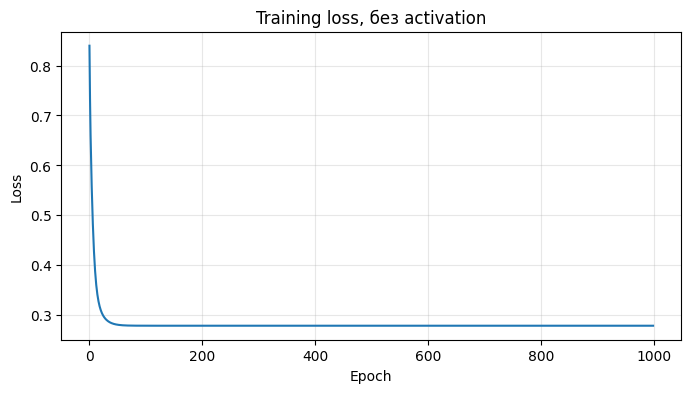

In [51]:
rng = np.random.default_rng(1)

W1 = rng.normal(0, np.sqrt(1/2), size=(2, 4))
b1 = np.zeros((1, 4))

W2 = rng.normal(0, np.sqrt(1/4), size=(4, 1))
b2 = np.zeros((1, 1))

lr = 0.3
losses = []

for epoch in range(1000):


    Z1 = X @ W1 + b1
    A1 = Z1
    Z2 = A1 @ W2 + b2
    Y_prob = sigmoid(Z2)


    loss = bce(y, Y_prob)
    losses.append(loss)


    y_col = y.reshape(-1, 1)
    m = len(X)

    dZ2 = (Y_prob - y_col) / m
    dW2 = A1.T @ dZ2
    db2 = dZ2.sum(axis=0, keepdims=True)

    dA1 = dZ2 @ W2.T
    dZ1 = dA1

    dW1 = X.T @ dZ1
    db1 = dZ1.sum(axis=0, keepdims=True)


    W1 -= lr*dW1
    b1 -= lr*db1
    W2 -= lr*dW2
    b2 -= lr*db2

print("Final loss:", losses[-1])
print("Accuracy:", accuracy_score(y, (Y_prob > 0.5).astype(int).ravel()))

plt.figure(figsize=(8, 4))
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Training loss, без activation")
plt.grid(alpha=0.3)
plt.show()

### Ответ
Почему сеть снова становится близкой к линейной модели? Без активации То есть весь выход это просто линейная функция от X с одной эффективной матрицей весов W1 и W2. Скрытый слой ничего нового не добавляет, граница получается прямой, как у персептрона.

### Эксперимент E. Плохая инициализация

Инициализация: zero
Final loss: 0.6931471805599453
Accuracy: 0.5
W1 после обучения:
[[0. 0. 0. 0.]
 [0. 0. 0. 0.]]


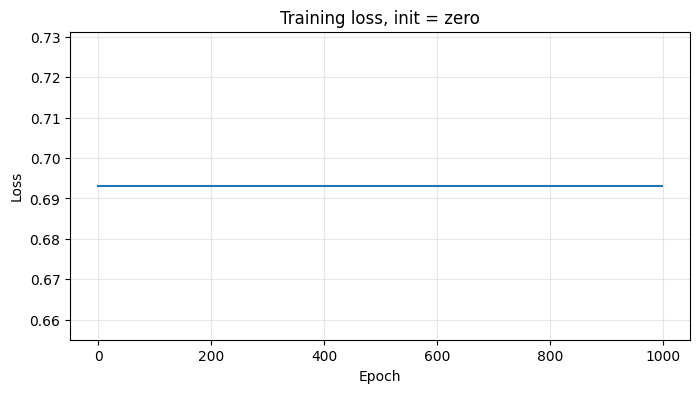

Инициализация: big
Final loss: 0.3608450616986003
Accuracy: 0.85
W1 после обучения:
[[ 8.15965279 -2.53166801 13.25024582 30.24856959]
 [-6.84935475 -4.80223341 31.45902285 15.74350157]]


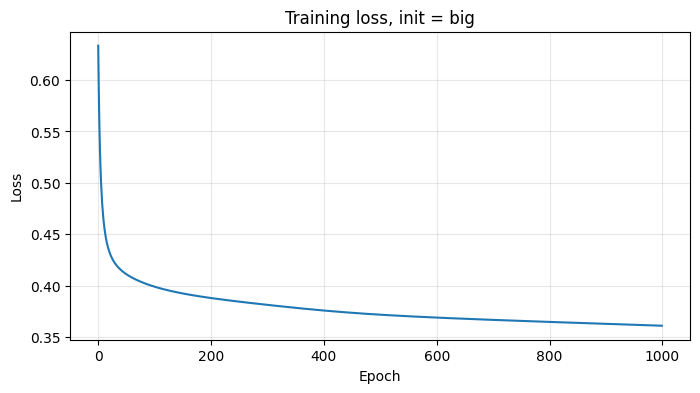

In [53]:
for init in ["zero", "big"]:
    rng = np.random.default_rng(1)

    W1 = rng.normal(0, np.sqrt(1/2), size=(2, 4))
    b1 = np.zeros((1, 4))

    W2 = rng.normal(0, np.sqrt(1/4), size=(4, 1))
    b2 = np.zeros((1, 1))

    if init == "zero":

        W1 = np.zeros((2, 4))
        W2 = np.zeros((4, 1))
    else:

        np.random.seed(42)
        W1 = np.random.randn(2, 4) * 20

    lr = 0.3
    losses = []

    for epoch in range(1000):

        Z1 = X @ W1 + b1
        A1 = np.tanh(Z1)
        Z2 = A1 @ W2 + b2
        Y_prob = sigmoid(Z2)


        loss = bce(y, Y_prob)
        losses.append(loss)


        y_col = y.reshape(-1, 1)
        m = len(X)

        dZ2 = (Y_prob - y_col) / m
        dW2 = A1.T @ dZ2
        db2 = dZ2.sum(axis=0, keepdims=True)

        dA1 = dZ2 @ W2.T
        dZ1 = dA1 * (1-A1**2)

        dW1 = X.T @ dZ1
        db1 = dZ1.sum(axis=0, keepdims=True)


        W1 -= lr*dW1
        b1 -= lr*db1
        W2 -= lr*dW2
        b2 -= lr*db2

    print("Инициализация:", init)
    print("Final loss:", losses[-1])
    print("Accuracy:", accuracy_score(y, (Y_prob > 0.5).astype(int).ravel()))
    print("W1 после обучения:")
    print(W1)

    plt.figure(figsize=(8, 4))
    plt.plot(losses)
    plt.xlabel("Epoch")
    plt.ylabel("Loss")
    plt.title(f"Training loss, init = {init}")
    plt.grid(alpha=0.3)
    plt.show()

### Ответы
Почему при нулевой инициализации скрытые нейроны ведут себя одинаково? Если у всех нейронов одинаковые (нулевые) веса, то на любом входе они выдают одно и то же.

Почему большие веса вместе с sigmoid могут привести к saturation и vanishing gradients? Когда веса очень большие, число z на входе в sigmoid получается огромным. У sigmoid на таких значениях график почти плоский: она выдаёт около 0 или около 1 и почти не меняется, если z чуть сдвинуть. Это и называется saturation, то есть насыщение. В backprop градиент умножается на наклон этого графика, а он почти нулевой, поэтому градиент тоже становится почти нулевым. Веса почти не обновляются, обучение стоит на месте. Это и есть vanishing gradients, то есть исчезающие градиенты

## 11. Gradient Check

In [55]:
epsilon = 1e-5
i, j = 0, 0

original = W1[i, j]

W1[i, j] = original + epsilon
Z1 = X @ W1 + b1
A1 = np.tanh(Z1)
Z2 = A1 @ W2 + b2
Y_prob = sigmoid(Z2)
loss_plus = bce(y, Y_prob)

W1[i, j] = original - epsilon
Z1 = X @ W1 + b1
A1 = np.tanh(Z1)
Z2 = A1 @ W2 + b2
Y_prob = sigmoid(Z2)
loss_minus = bce(y, Y_prob)

W1[i, j] = original

numerical_grad = (loss_plus - loss_minus) / (2*epsilon)

print("Backprop:", dW1[i, j])
print("Numerical:", numerical_grad)


Backprop: 0.0056465664055825125
Numerical: 0.005647591394541961


### Ответы
Зачем нужен gradient check?
Он нужен для проверки правильности реализации backpropagation. Аналитический градиент сравнивается с численным приближением производной

Что может означать большая разница между analytical и numerical gradient?
Чаще всего это указывает на ошибку в формулах backpropagation, неверный знак, неправильную размерность или ошибку в коде вычисления функции потерь

## 12. Самостоятельная часть: Neural Network Challenge

In [56]:
from sklearn.datasets import make_circles

X, y = make_circles(
    n_samples=500,
    noise=0.10,
    factor=0.45,
    random_state=42
)


In [58]:
configs = [
    (2, "tanh", 0.3, 1000),
    (4, "sigmoid", 0.3, 1000),
    (4, "tanh", 0.3, 100),
    (4, "tanh", 0.3, 1000),
    (8, "relu", 1.0, 1000),
]

for k, (n, act, lr, n_epochs) in enumerate(configs, start=1):
    rng = np.random.default_rng(1)

    W1 = rng.normal(0, np.sqrt(1/2), size=(2, n))
    b1 = np.zeros((1, n))

    W2 = rng.normal(0, np.sqrt(1/n), size=(n, 1))
    b2 = np.zeros((1, 1))

    losses = []

    for epoch in range(n_epochs):


        Z1 = X @ W1 + b1
        if act == "tanh":
            A1 = np.tanh(Z1)
        elif act == "sigmoid":
            A1 = sigmoid(Z1)
        else:
            A1 = relu(Z1)
        Z2 = A1 @ W2 + b2
        Y_prob = sigmoid(Z2)


        loss = bce(y, Y_prob)
        losses.append(loss)


        y_col = y.reshape(-1, 1)
        m = len(X)

        dZ2 = (Y_prob - y_col) / m
        dW2 = A1.T @ dZ2
        db2 = dZ2.sum(axis=0, keepdims=True)

        dA1 = dZ2 @ W2.T
        if act == "tanh":
            dZ1 = dA1 * (1-A1**2)
        elif act == "sigmoid":
            dZ1 = dA1 * A1 * (1-A1)
        else:
            dZ1 = dA1 * (Z1 > 0)

        dW1 = X.T @ dZ1
        db1 = dZ1.sum(axis=0, keepdims=True)


        W1 -= lr*dW1
        b1 -= lr*db1
        W2 -= lr*dW2
        b2 -= lr*db2

    print("Эксперимент", k, "| нейронов:", n, "| activation:", act, "| lr:", lr, "| эпох:", n_epochs)
    print("Final loss:", losses[-1])
    print("Accuracy:", accuracy_score(y, (Y_prob > 0.5).astype(int).ravel()))
    print()

Эксперимент 1 | нейронов: 2 | activation: tanh | lr: 0.3 | эпох: 1000
Final loss: 0.4580173554689849
Accuracy: 0.786

Эксперимент 2 | нейронов: 4 | activation: sigmoid | lr: 0.3 | эпох: 1000
Final loss: 0.6930572212704076
Accuracy: 0.512

Эксперимент 3 | нейронов: 4 | activation: tanh | lr: 0.3 | эпох: 100
Final loss: 0.6861250147742153
Accuracy: 0.596

Эксперимент 4 | нейронов: 4 | activation: tanh | lr: 0.3 | эпох: 1000
Final loss: 0.11998928613832933
Accuracy: 0.98

Эксперимент 5 | нейронов: 8 | activation: relu | lr: 1.0 | эпох: 1000
Final loss: 0.015865238969206535
Accuracy: 1.0



## 13. Финальный эксперимент: «Сломайте и восстановите модель»

Bad version:   final loss = 0.2188747153201255 accuracy = 0.9433333333333334
Fixed version: final loss = 0.286550069011813 accuracy = 0.8833333333333333


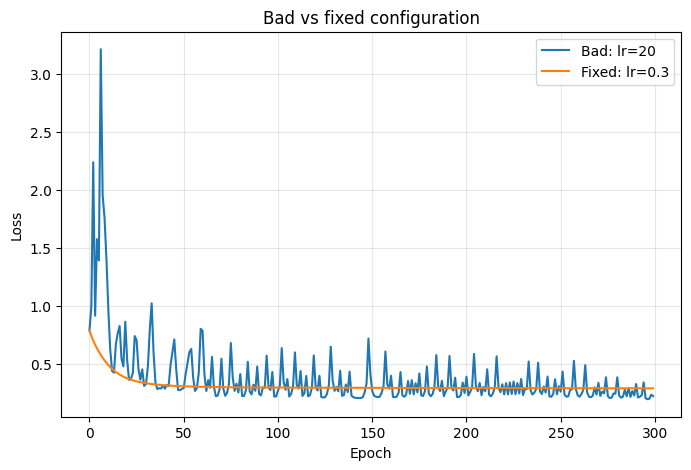

In [41]:
def train_bad_or_fixed(lr=3.0, epochs=300):
    losses, acc = train_moons(lr=lr, epochs=epochs, activation="tanh")
    return losses, acc

bad_losses, bad_acc = train_bad_or_fixed(lr=20.0, epochs=300)
fixed_losses, fixed_acc = train_bad_or_fixed(lr=0.3, epochs=300)

print("Bad version:   final loss =", bad_losses[-1], "accuracy =", bad_acc)
print("Fixed version: final loss =", fixed_losses[-1], "accuracy =", fixed_acc)

plt.figure(figsize=(8, 5))
plt.plot(bad_losses, label="Bad: lr=20")
plt.plot(fixed_losses, label="Fixed: lr=0.3")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("Bad vs fixed configuration")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

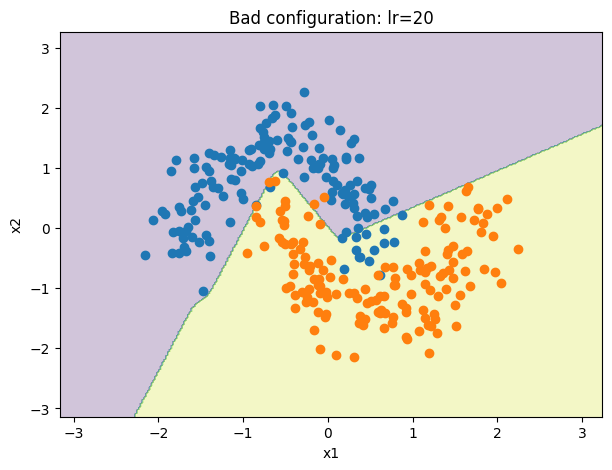

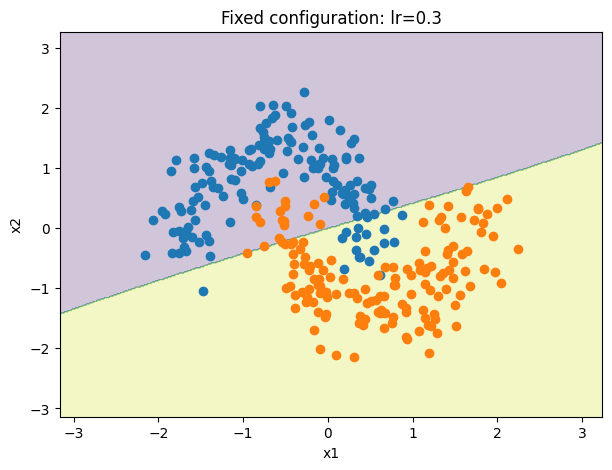

In [42]:
def decision_boundary_from_parameters(hidden_layers=(4,), activation="tanh",
                                      lr=0.3, epochs=300, seed=1):
    rng = np.random.default_rng(seed)
    dims = [2] + list(hidden_layers) + [1]
    W = [rng.normal(0, np.sqrt(1/dims[k]), size=(dims[k], dims[k+1]))
         for k in range(len(dims)-1)]
    b = [np.zeros((1, dims[k+1])) for k in range(len(dims)-1)]

    for _ in range(epochs):
        A=[X]; Z=[]
        for k in range(len(W)):
            z=A[-1]@W[k]+b[k]; Z.append(z)
            if k == len(W)-1:
                A.append(sigmoid(z))
            elif activation=="tanh":
                A.append(np.tanh(z))
            else:
                A.append(relu(z))
        d=(A[-1]-y.reshape(-1,1))/len(X)
        for k in range(len(W)-1,-1,-1):
            dW=A[k].T@d; db=d.sum(0,keepdims=True)
            if k>0:
                da=d@W[k].T
                if activation=="tanh":
                    da*=1-A[k]**2
                else:
                    da*=(Z[k-1]>0)
                d=da
            W[k]-=lr*dW; b[k]-=lr*db

    return W,b

def plot_mlp_boundary(W,b,title):
    x_min,x_max=X[:,0].min()-1,X[:,0].max()+1
    y_min,y_max=X[:,1].min()-1,X[:,1].max()+1
    xx,yy=np.meshgrid(np.linspace(x_min,x_max,300),np.linspace(y_min,y_max,300))
    grid=np.c_[xx.ravel(),yy.ravel()]
    A=grid
    for k in range(len(W)):
        z=A@W[k]+b[k]
        A=sigmoid(z) if k==len(W)-1 else np.tanh(z)
    zz=(A>=.5).astype(int).reshape(xx.shape)
    plt.figure(figsize=(7,5))
    plt.contourf(xx,yy,zz,alpha=.25)
    plt.scatter(X[y==0,0],X[y==0,1])
    plt.scatter(X[y==1,0],X[y==1,1])
    plt.title(title)
    plt.xlabel("x1"); plt.ylabel("x2")
    plt.show()

W_bad,b_bad=decision_boundary_from_parameters(lr=20,epochs=300)
W_fix,b_fix=decision_boundary_from_parameters(lr=.3,epochs=300)
plot_mlp_boundary(W_bad,b_bad,"Bad configuration: lr=20")
plot_mlp_boundary(W_fix,b_fix,"Fixed configuration: lr=0.3")

### Ответы
Почему первая версия обучалась плохо? В плохой версии использован слишком большой learning rate. Обновления весов становятся чрезмерными, поэтому оптимизация может нестабильно двигаться по функции потерь и пропускать область минимума.

Как именно выбранное изменение улучшило обучение?
Мы изменили только learning rate: с 20 на 0.3. Размер шага стал значительно меньше, поэтому веса обновляются более плавно, loss уменьшается стабильнее, а граница решений становится более осмысленной.

## 14. Письменные ответы

### 1. Почему одного персептрона недостаточно для make_moons и make_circles?
Персептрон строит линейную границу. make_moons и make_circles имеют нелинейную структуру, поэтому одной прямой для их разделения недостаточно.

### 2. Зачем нужен hidden layer?
Скрытый слой преобразует исходные признаки в новое представление и позволяет модели строить более сложные зависимости.

### 3. Зачем нужна нелинейная activation function?
Нелинейность позволяет нескольким слоям создавать нелинейную границу решения. Без неё последовательность линейных преобразований остаётся эквивалентной одному линейному преобразованию.

### 4. Что показывает loss и чем он отличается от accuracy?
Loss показывает, насколько предсказания модели отличаются от правильных ответов, причём учитывает уверенность модели. Accuracy показывает долю правильно классифицированных объектов. Поэтому accuracy может быть высокой даже тогда, когда вероятностные предсказания модели неидеальны.

### 5. Что делает backpropagation?
Backpropagation вычисляет градиенты функции потерь по весам сети, проходя от выхода сети к её входу.

### 6. Что показывает gradient?
Градиент показывает направление и скорость изменения функции потерь при изменении параметров модели.

### 7. Почему веса обновляются в направлении -gradient?
Потому что gradient указывает направление наибольшего роста loss. Движение в противоположную сторону уменьшает функцию потерь.

### 8. Что происходит при слишком маленьком learning rate?
Обучение становится очень медленным, потому что параметры изменяются маленькими шагами.

### 9. Что происходит при слишком большом learning rate?
Обновления становятся слишком большими, из-за чего loss может колебаться или обучение может стать нестабильным.

### 10. Почему нулевая инициализация проблемна?
При одинаковых нулевых весах скрытые нейроны получают одинаковые значения и одинаковые градиенты. Они не начинают учиться разным признакам.

### 11. Что такое vanishing gradient?
Это ситуация, когда градиенты становятся очень маленькими, поэтому веса предыдущих слоёв почти не обновляются. Такое может происходить, например, при насыщении sigmoid или tanh.

### 12. Зачем нужен gradient check?
Gradient check позволяет сравнить градиент, полученный аналитически через backpropagation, с численной производной и обнаружить ошибки в реализации.